## Radio Astronomy Imaging
Jupyter Notebook, code written by:  
6344569 Mathijs Bos  
5866642 Tycho Brouwer  

### Initial Setup

In [ ]:
import numpy as np
import scipy.io
import matplotlib.pyplot as plt
np.set_printoptions(suppress=True)

mat = scipy.io.loadmat('lofar_data/lofar_DSP_data_1.mat')

print([k for k in mat.keys() if not k.startswith("__")])
ans = mat["ans"]
freq = np.squeeze(mat["freq"])
poslocal = mat["poslocal"]
t_obs = np.squeeze(mat["t_obs_matlab"])
lon = np.squeeze(mat["lon"])
lat = np.squeeze(mat["lat"])
Rh = mat["Rh"]

c = 299792458
p = len(Rh) # number of receiving elements
lambd = c / freq

x = poslocal[:, 0]
y = poslocal[:, 1]
dist = np.sqrt((x[:,None] - x[None, :])**2 + (y[:,None] - y[None,:])**2)

D = np.max(dist)

dl = 0.25 * lambd / D

l = np.arange(0, 1, dl)
l = np.concatenate((-np.flipud(l[1:]), l))

m = l.copy()

r = poslocal - poslocal.mean(axis=0)
r = r[:, 0:2]

['ans', 'freq', 'poslocal', 't_obs_matlab', 'lon', 'lat', 'Rh']


In [202]:
print(len(l))
print(Rh.shape)
print(len(l)*len(m))

print("Δx =", np.max(poslocal[:, 0]) - np.min(poslocal[:, 0]))
print("Δy =", np.max(poslocal[:, 1]) - np.min(poslocal[:, 1]))
print("Δz =", np.max(poslocal[:, 2]) - np.min(poslocal[:, 2]))

513
(273, 273)
263169
Δx = 285.2418252498203
Δy = 293.10147869214416
Δz = 0.0020737163722515106


### Periodogram Solution (classical beamforming)
This solution simply calculates:
$P = a^H R_h a$

In [203]:
P = np.zeros((len(m), len(l)))

for i in range(len(m)):
    for j in range(len(l)):
        m0 = m[i]
        l0 = l[j]

        s = np.array([l0, m0])
        a = np.exp(-2j*np.pi/lambd * (r@s))
        P[i,j] = np.real(a.conj() @ Rh @ a)

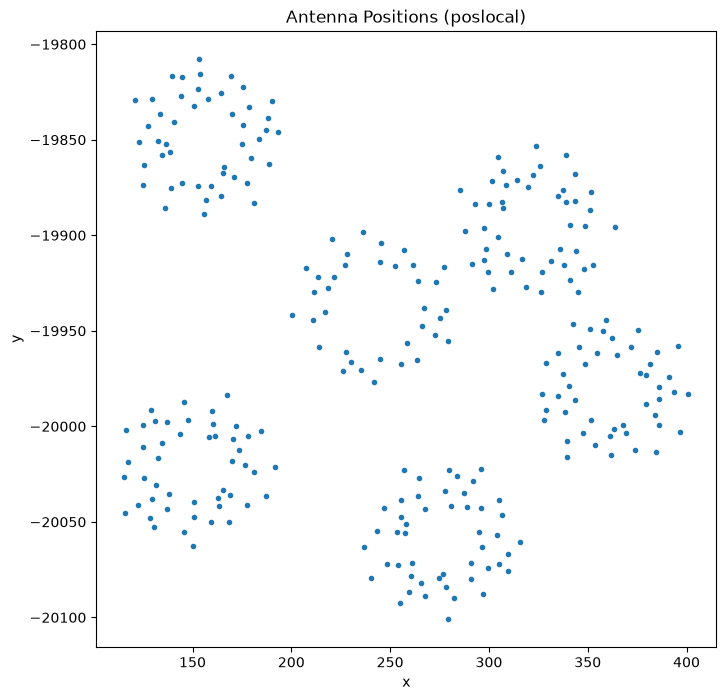

In [204]:
plt.figure(figsize=(8,8))
plt.plot(poslocal[:,0], poslocal[:,1], '.')
plt.title("Antenna Positions (poslocal)")
plt.xlabel("x")
plt.ylabel("y")
plt.savefig("Antennas.svg", format="svg", bbox_inches="tight")

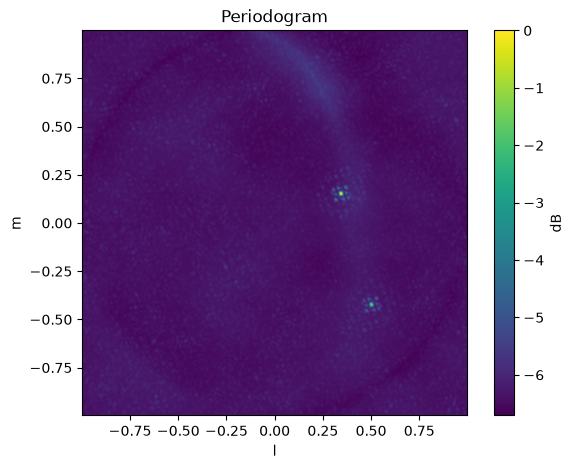

In [205]:
P_dB = 10 * np.log10(P / np.nanmax(P))

plt.figure(figsize=(7,5))
plt.imshow(P_dB, extent=[l.min(), l.max(), m.min(), m.max()])
plt.colorbar(label='dB')
plt.title("Periodogram")
plt.xlabel('l')
plt.ylabel('m')
plt.savefig("Periodogram.svg", format="svg", bbox_inches="tight")

### MVDR
$I'_D =  \sum^{K}_{k=1} 1/(a^H(S)\; \hat{R}^{-1}\; a(S)) $

In [206]:
P = np.zeros((len(m), len(l)))
Rinv = np.linalg.inv(Rh)

for i in range(len(m)):
    for j in range(len(l)):
        s = np.array([l[j], m[i]])
        a = np.exp(-2j * np.pi / lambd * (r @ s))
        P[i, j] = 1/ np.real(np.conj(a).T @ Rinv @ a)

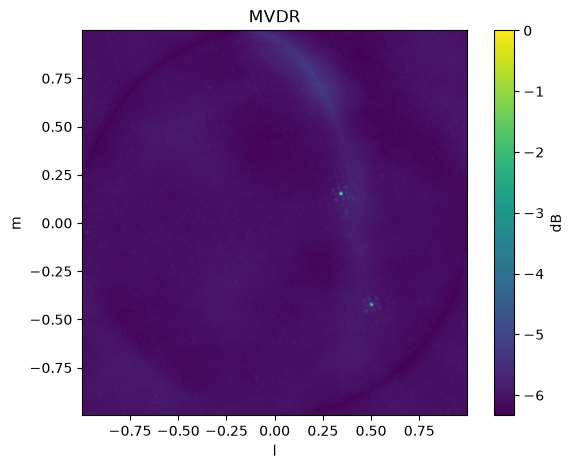

In [207]:
P_dB = 10 * np.log10(P / np.nanmax(P))

plt.figure(figsize=(7,5))
plt.imshow(P_dB, extent=[l.min(), l.max(), m.min(), m.max()])
plt.colorbar(label='dB')
plt.title("MVDR")
plt.xlabel('l')
plt.ylabel('m')
plt.savefig("MVDR.svg", format="svg", bbox_inches="tight")

### MUSIC

In [208]:
P = np.zeros((len(m), len(l)))
eigenvalues, eigenvectors = np.linalg.eigh(Rh)
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

k_list = [5, 10, 25, 50, 90, 140, 180, 210, 245]
P_dB = np.zeros((len(k_list), len(m), len(l)))

for k in range(len(k_list)):
    Un = eigenvectors[:, k_list[k]:] #Number of sources, usefull for filtering, leaving empty add tons of noise
    Pn = Un @ np.conj(Un).T

    for i in range(len(m)):
        for j in range(len(l)):
            s = np.array([l[j], m[i]])
            a = np.exp(-2j * np.pi / lambd * (r @ s))
            P[i, j] = 1/np.real(np.conj(a) @ Pn @ a)
    
    P_dB[k] = 10 * np.log10(P / np.nanmax(P))

    print("completed k=", k_list[k])

completed k= 5
completed k= 10
completed k= 25
completed k= 50
completed k= 90
completed k= 140
completed k= 180
completed k= 210
completed k= 245


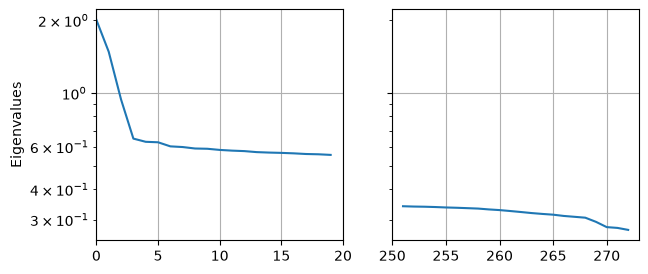

In [209]:
fig, axs = plt.subplots(1, 2, sharey=True, figsize=(7,3))
axs[0].semilogy(np.arange(20), eigenvalues[:20])
axs[1].semilogy(np.arange(251,273), eigenvalues[251:])
axs[0].set_xlim(0,20)
axs[1].set_xlim(250,273)
axs[0].set_ylabel("Eigenvalues")
axs[0].grid(True)
axs[1].grid(True)
plt.savefig("Eigenvalues.svg", format="svg", bbox_inches="tight")

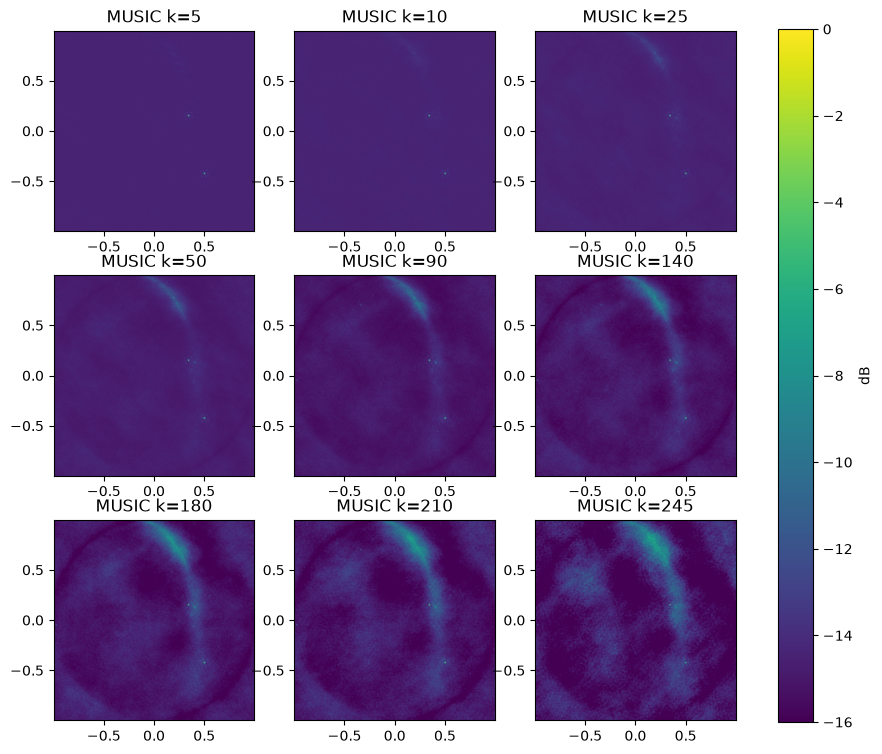

In [ ]:
fig, axs = plt.subplots(3,3, figsize=(11,9))
for k in range(len(k_list)):
    im = axs[k//3, k%3].imshow(P_dB[k], extent=[l.min(), l.max(), m.min(), m.max()], vmin=-16, vmax=0)
    axs[k//3, k%3].set_title("MUSIC k=%i" %k_list[k])

fig.colorbar(im, label='dB', ax=axs, location ="right")
plt.savefig("MUSIC.svg", format="svg", bbox_inches="tight")

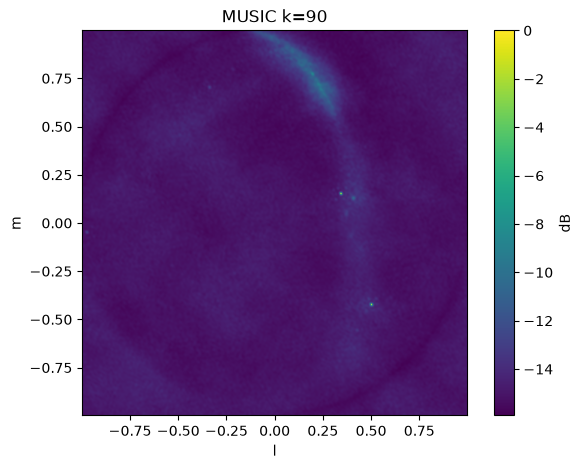

In [211]:
plt.figure(figsize=(7,5))
plt.imshow(P_dB[4], extent=[l.min(), l.max(), m.min(), m.max()])
plt.colorbar(label='dB')
plt.title("MUSIC k=90")
plt.xlabel('l')
plt.ylabel('m')
plt.savefig("AAR.svg", format="svg", bbox_inches="tight")

### Adaptive Angular Response (AAR)

In [212]:
P = np.zeros((len(m), len(l)))
Rinv2 = Rinv @ Rinv

for i in range(len(m)):
    for j in range(len(l)):
        s = np.array([l[j], m[i]])
        a = np.exp(-2j * np.pi / lambd * (r @ s))
        P[i, j] = ((np.conj(a).T @ Rinv @ a) / (a.conj().T @ Rinv2 @ a))**2

C:\Users\mathi\AppData\Local\Temp\ipykernel_27424\3529747190.py:8: ComplexWarning: Casting complex values to real discards the imaginary part
  P[i, j] = ((np.conj(a).T @ Rinv @ a) / (a.conj().T @ Rinv2 @ a))**2


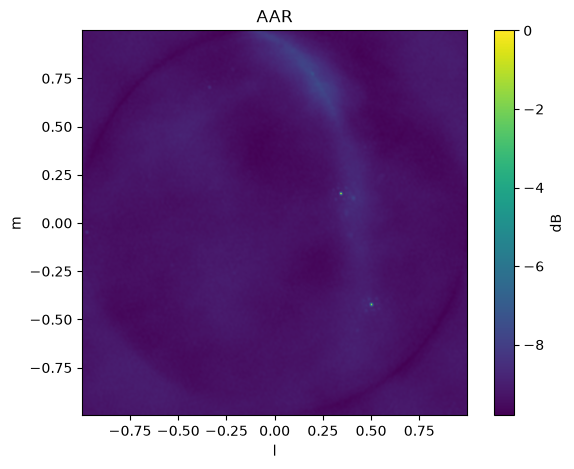

In [213]:
P_dB = 10 * np.log10(P / np.nanmax(P))

plt.figure(figsize=(7,5))
plt.imshow(P_dB, extent=[l.min(), l.max(), m.min(), m.max()])
plt.colorbar(label='dB')
plt.title("AAR")
plt.xlabel('l')
plt.ylabel('m')
plt.savefig("AAR.svg", format="svg", bbox_inches="tight")